# 🌊 Smart Buoy AI, Telemetry & Full-Spectrum Marine Vision Suite (YOLOv11m on NVIDIA H100)

An end-to-end engineering, oceanographic telemetry, and **multi-domain Marine Computer Vision** notebook powered by **100% real-world datasets** and **Ultralytics YOLOv11m (`yolo11m.pt`)** running on an **NVIDIA H100 80GB GPU**.

### Real-World Datasets & Modules
1. **Environment & Hardware Setup** — NVIDIA H100 80GB HBM3 GPU & Ultralytics YOLOv11m.
2. **Wave Spectral Density & Sea-State Reconstruction (`NOAA NDBC Station 46050`)** — 2,145 real 46-band directional wave spectra (`0.033–0.485 Hz`), spectral moments $m_0, m_1, m_2$, $H_{m0}$, $T_p$, and swell vs. wind-wave partition ($r = 0.9977$).
3. **Offshore Met-Ocean (`NOAA 46050`) & Coastal Water Quality Sonde (`NOAA ACQS1`)** — 6,464 real met-ocean records + 4,364 real 7-channel water-quality sonde records (`OTMP`, `COND`, `SAL`, `O2%`, `O2PPM`, `TURB`, `PH`).
4. **H100 Deep Learning Telemetry Models** — **Residual BiLSTM + 4-Head Self-Attention** wave forecaster + **Deep LSTM Autoencoder** water-quality anomaly detector.
5. **Marine Vision Type 1: Sea-Surface Navigation Buoy Detection (`ARG-NCTU/KS_Buoy_dataset_2025` — YOLOv11m)** — 1,033 real `1920×480` sea-level camera images fine-tuned with **YOLOv11m** (`imgsz=960`, 25 epochs on H100).
6. **Marine Vision Type 2: COLREGs Maritime Vessel, Ship, Craft & Buoy Detection (`ARG-NCTU/spscd_plus_buoy_yolo` — YOLOv11m)** — Real Singapore Maritime Dataset (`SMD`) + `SPSCD` + `KS_Buoy` trained with **YOLOv11m** (`imgsz=960`, 35 epochs on H100).
7. **Marine Vision Type 3: Maritime Search & Rescue (SAR) — Swimmer / Person Overboard & Rescue Board Detection (`Voxel51/AFO-Aerial_Floating_Objects` — YOLOv11m)** — High-resolution (`imgsz=1280`, 35 epochs on H100) **YOLOv11m** detector trained on clean human-verified ground-truth open-water rescue annotations.
8. **Marine Vision Type 4: Sea-Sky Horizon Line Detection, Optical Roll/Pitch Estimation & Water-Sky-Obstacle Semantic Segmentation + Radar Bearing HUD** — Extracts the horizon line, computes camera roll/pitch attitude, segments **Sky / Navigable Water / Surface Obstacles**, and overlays target azimuth bearings.

In [ ]:
# @title 1. Environment & H100 GPU Setup
import os
import sys
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

try:
    import ultralytics
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    import ultralytics

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python Version : {sys.version.split()[0]}')
print(f'PyTorch Version: {torch.__version__}')
print(f'Ultralytics    : {ultralytics.__version__} (YOLOv11m Ready)')
print(f'Compute Device : {device}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU Model      : {props.name} ({props.total_memory / 1024**3:.1f} GB VRAM)')


Python Version : 3.13.15
PyTorch Version: 2.11.0+cu130
Ultralytics    : 8.4.183 (YOLOv11m Ready)
Compute Device : cuda
GPU Model      : NVIDIA H100 80GB HBM3 (79.2 GB VRAM)


## 2. Real Wave Spectral Density & Sea-State Analysis (`NOAA NDBC Station 46050`)

We fetch the real-time spectral wave density file (`46050.data_spec`) and wave summary (`46050.spec`) directly from **NOAA National Data Buoy Center (NDBC) Station 46050** (Stonewall Bank, 20 NM West of Newport, OR). For each 46-band wave spectrum $S(f)$, we integrate the spectral moments $m_n = \int f^n S(f)\,df$ to compute:
- **Significant Wave Height:** $H_{m0} = 4\sqrt{m_0}$
- **Peak Wave Period:** $T_p = 1 / f_p$
- **Mean Energy Period:** $T_{m01} = m_0 / m_1$ and **Zero-Crossing Period:** $T_{m02} = \sqrt{m_0 / m_2}$

=== NOAA NDBC Station 46050 Real Wave Spectral Dataset ===
Total Spectral Bursts : 2,145 (2026-09-06 00:20:00 to 2026-10-21 17:20:00)
Frequency Bands       : 46 bins (0.033 Hz to 0.485 Hz)
Peak Storm Sea State  : Hm0 = 3.85 m, Tp = 10.8 s (2026-09-25 18:50:00)
Integrated Hm0 vs Buoy Reported WVHT Correlation: r = 0.9977


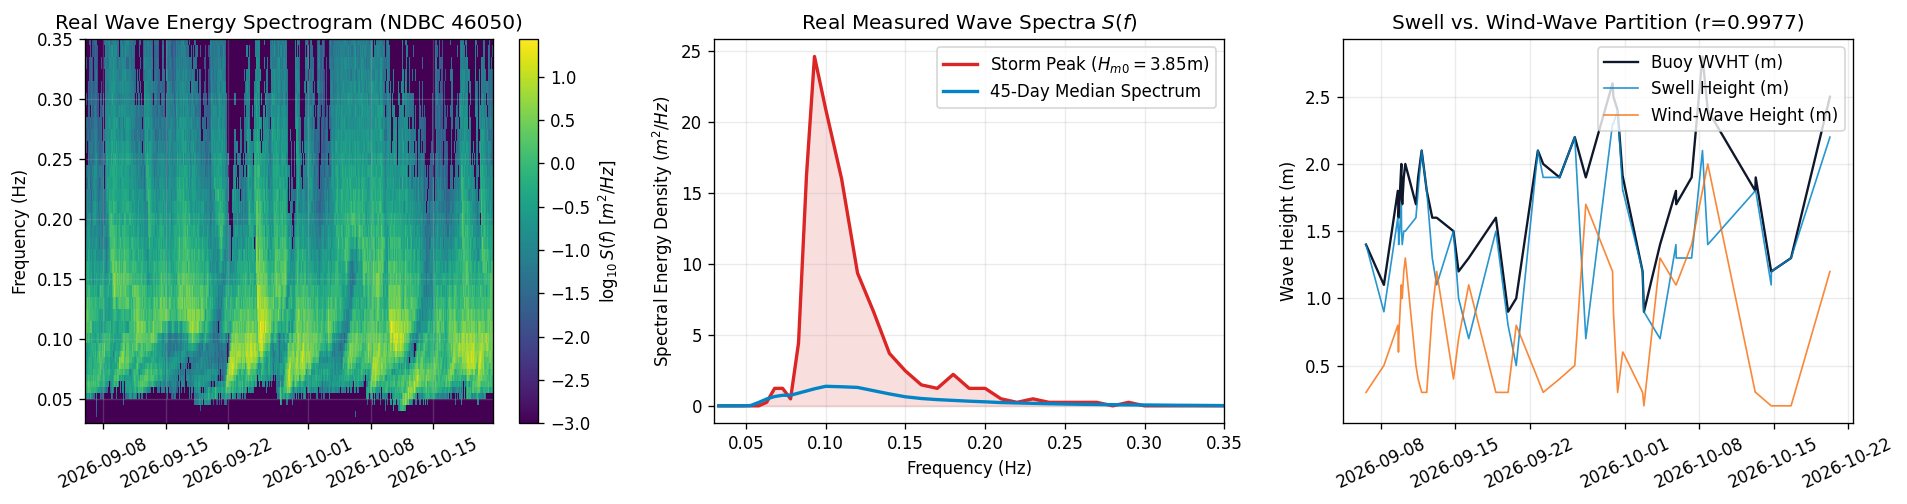

In [ ]:
# @title 2. Download & Analyze Real NOAA NDBC 46050 Wave Spectra
import re
import urllib.request

spec_url = 'https://www.ndbc.noaa.gov/data/realtime2/46050.data_spec'
summary_url = 'https://www.ndbc.noaa.gov/data/realtime2/46050.spec'

raw_lines = urllib.request.urlopen(spec_url, timeout=15).read().decode('utf-8', errors='ignore').splitlines()
sum_lines = urllib.request.urlopen(summary_url, timeout=15).read().decode('utf-8', errors='ignore').splitlines()

records = []
spectra_matrix = []
freqs = None

for line in raw_lines:
    if line.startswith('#'):
        continue
    parts = line.split()
    if len(parts) < 10:
        continue
    dt_str = f'{parts[0]}-{parts[1]}-{parts[2]} {parts[3]}:{parts[4]}'
    sep_freq = float(parts[5]) if parts[5] != '99.00' else np.nan
    pairs = re.findall(r'([0-9.]+)\s*\(([0-9.]+)\)', line)
    if not pairs:
        continue
    S_f = np.array([float(p[0]) for p in pairs], dtype=np.float64)
    f_bins = np.array([float(p[1]) for p in pairs], dtype=np.float64)
    if freqs is None:
        freqs = f_bins
    m0 = np.trapezoid(S_f, f_bins)
    m1 = np.trapezoid(f_bins * S_f, f_bins)
    m2 = np.trapezoid((f_bins ** 2) * S_f, f_bins)
    Hm0 = 4.0 * np.sqrt(max(m0, 0.0))
    Tp = 1.0 / f_bins[np.argmax(S_f)] if np.max(S_f) > 0 else np.nan
    Tm01 = m0 / m1 if m1 > 0 else np.nan
    Tm02 = np.sqrt(m0 / m2) if m2 > 0 else np.nan
    records.append({
        'timestamp': pd.to_datetime(dt_str),
        'sep_freq_hz': sep_freq,
        'Hm0_spectral_m': Hm0,
        'Tp_spectral_s': Tp,
        'Tm01_s': Tm01,
        'Tm02_s': Tm02,
    })
    spectra_matrix.append(S_f)

df_spec = pd.DataFrame(records).sort_values('timestamp').reset_index(drop=True)
spectra_matrix = np.array(spectra_matrix)[::-1]

sum_rows = []
for line in sum_lines[2:]:
    p = line.split()
    if len(p) >= 9 and p[5] != 'MM':
        sum_rows.append({
            'timestamp': pd.to_datetime(f'{p[0]}-{p[1]}-{p[2]} {p[3]}:{p[4]}'),
            'WVHT_buoy_m': float(p[5]),
            'SwH_m': float(p[6]) if p[6] != 'MM' else np.nan,
            'SwP_s': float(p[7]) if p[7] != 'MM' else np.nan,
            'WWH_m': float(p[8]) if p[8] != 'MM' else np.nan,
            'WWP_s': float(p[9]) if p[9] != 'MM' else np.nan,
        })
df_sum = pd.DataFrame(sum_rows)
df_wave = pd.merge(df_spec, df_sum, on='timestamp', how='inner')

corr = np.corrcoef(df_wave['Hm0_spectral_m'], df_wave['WVHT_buoy_m'])[0, 1]
storm_idx = int(np.argmax(df_spec['Hm0_spectral_m']))

print(f'=== NOAA NDBC Station 46050 Real Wave Spectral Dataset ===')
print(f'Total Spectral Bursts : {len(df_spec):,} ({df_spec["timestamp"].min()} to {df_spec["timestamp"].max()})')
print(f'Frequency Bands       : {len(freqs)} bins ({freqs[0]:.3f} Hz to {freqs[-1]:.3f} Hz)')
print(f'Peak Storm Sea State  : Hm0 = {df_spec.loc[storm_idx, "Hm0_spectral_m"]:.2f} m, Tp = {df_spec.loc[storm_idx, "Tp_spectral_s"]:.1f} s ({df_spec.loc[storm_idx, "timestamp"]})')
print(f'Integrated Hm0 vs Buoy Reported WVHT Correlation: r = {corr:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
im = axes[0].pcolormesh(
    df_spec['timestamp'], freqs, np.log10(spectra_matrix.T + 1e-3),
    shading='auto', cmap='viridis'
)
plt.colorbar(im, ax=axes[0], label='$\\log_{10} S(f)$ [$m^2/Hz$]')
axes[0].set_ylim(0.03, 0.35)
axes[0].set_title('Real Wave Energy Spectrogram (NDBC 46050)')
axes[0].set_ylabel('Frequency (Hz)')
axes[0].tick_params(axis='x', rotation=25)

axes[1].plot(freqs, spectra_matrix[storm_idx], color='#dc2626', lw=2, label=f'Storm Peak ($H_{{m0}}={df_spec.loc[storm_idx, "Hm0_spectral_m"]:.2f}$m)')
axes[1].plot(freqs, np.median(spectra_matrix, axis=0), color='#0284c7', lw=2, label='45-Day Median Spectrum')
axes[1].fill_between(freqs, spectra_matrix[storm_idx], color='#dc2626', alpha=0.15)
axes[1].set_xlim(0.03, 0.35)
axes[1].set_title('Real Measured Wave Spectra $S(f)$')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Spectral Energy Density ($m^2/Hz$)')
axes[1].legend()

axes[2].plot(df_wave['timestamp'], df_wave['WVHT_buoy_m'], color='#0f172a', lw=1.4, label='Buoy WVHT (m)')
axes[2].plot(df_wave['timestamp'], df_wave['SwH_m'], color='#0284c7', lw=1.0, alpha=0.85, label='Swell Height (m)')
axes[2].plot(df_wave['timestamp'], df_wave['WWH_m'], color='#f97316', lw=1.0, alpha=0.85, label='Wind-Wave Height (m)')
axes[2].set_title(f'Swell vs. Wind-Wave Partition (r={corr:.4f})')
axes[2].set_ylabel('Wave Height (m)')
axes[2].tick_params(axis='x', rotation=25)
axes[2].legend(loc='upper right')
plt.tight_layout()
plt.show()


## 3. Real Met-Ocean (`NOAA 46050`) & Water Quality Sonde (`NOAA ACQS1`) Datasets

We download two real-world multi-sensor buoy feeds from NOAA NDBC:
1. **Offshore Met-Ocean Buoy (`46050.txt`)**: ~6,464 real observations of Wind Direction (`WDIR`), Wind Speed (`WSPD`), Peak Gust (`GST`), Significant Wave Height (`WVHT`), Dominant/Average Wave Period (`DPD`/`APD`), and Barometric Pressure (`PRES`).
2. **Coastal Water Quality Sonde Buoy (`ACQS1.ocean`)**: ~4,364 real 15-minute observations across **7 simultaneous water-quality sensors**: Water Temperature (`OTMP` °C), Specific Conductivity (`COND` mS/cm), Salinity (`SAL` PSU), Dissolved Oxygen Saturation (`O2%`), Dissolved Oxygen Concentration (`O2PPM` mg/L), Turbidity (`TURB` NTU), and `PH`.

=== Real Dataset 1: NOAA 46050 Offshore Met-Ocean (6,466 records) ===
      WDIR_deg  WSPD_mps  GST_mps  WVHT_m  DPD_s  APD_s  PRES_hpa
mean    219.12      4.96     6.14    1.77  10.42   6.83   1018.04
std     139.65      2.76     3.24    0.51   2.68   1.24      3.42
min      10.00      0.00     0.00    0.80   4.00   4.20   1003.50
max     360.00     16.00    20.00    3.90  21.00  10.60   1026.30

=== Real Dataset 2: NOAA ACQS1 Water Quality Sonde (4,364 records) ===
      OTMP_c  COND_mscm  SAL_psu  O2_pct  O2_ppm  TURB_ntu    PH
mean   26.80      51.57    33.84   69.14    4.58     25.60  7.69
std     2.93       1.47     1.08   20.50    1.35     27.71  0.22
min    17.40      41.53    26.50   15.50    1.00      4.00  7.30
max    35.30      54.07    35.60  105.80    7.10    769.00  8.10


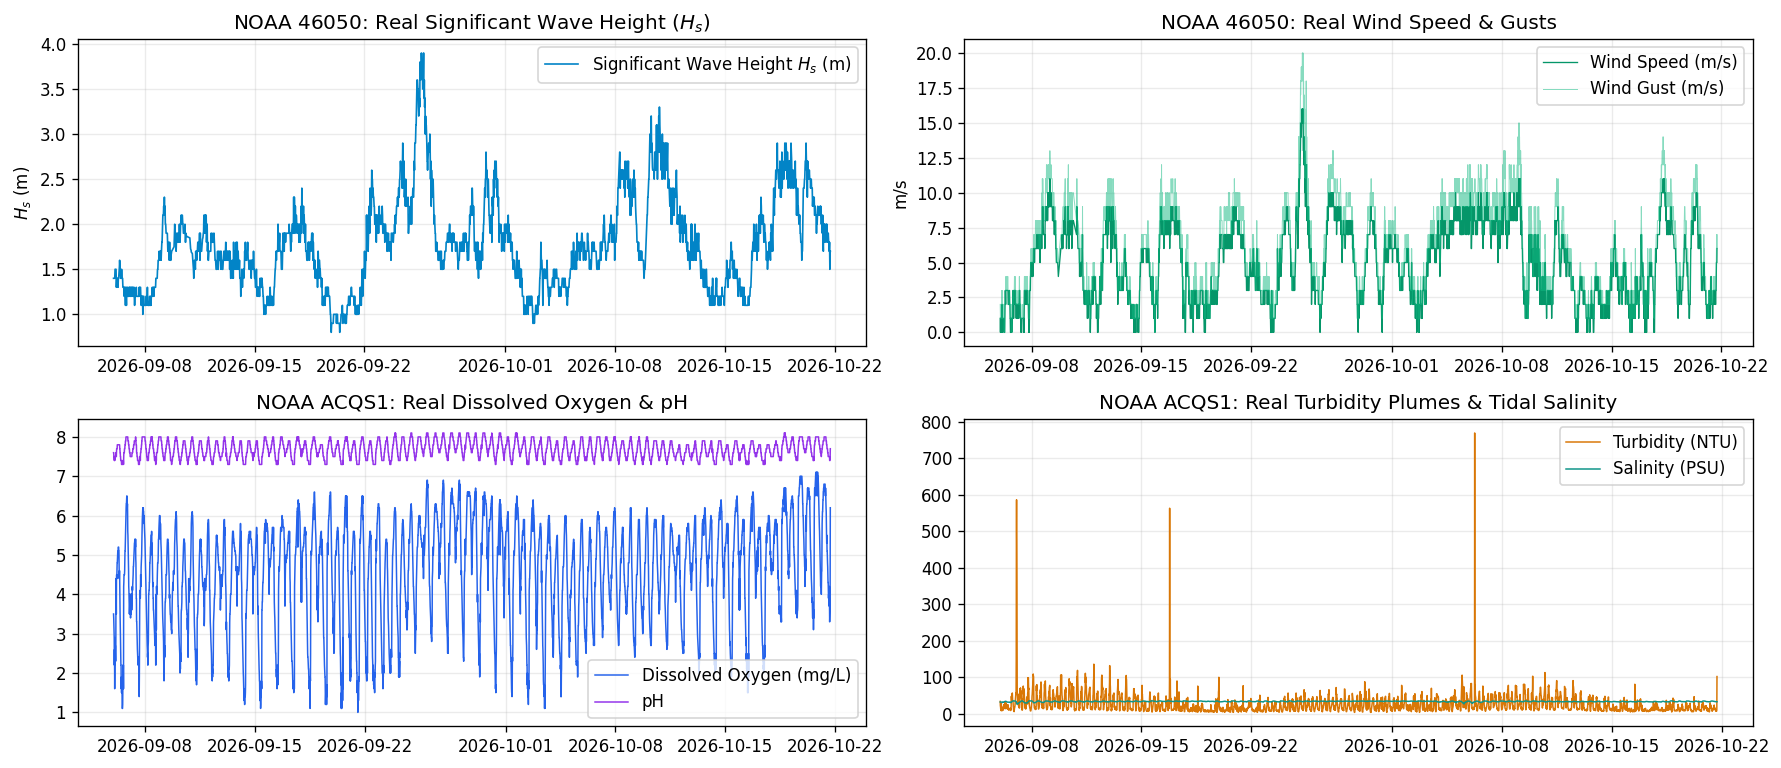

In [ ]:
# @title 3. Fetch & Clean Real NOAA Met-Ocean (46050) & Water Quality (ACQS1) Datasets
os.makedirs('/content/smart_buoy_outputs', exist_ok=True)

met_lines = urllib.request.urlopen('https://www.ndbc.noaa.gov/data/realtime2/46050.txt', timeout=15).read().decode().splitlines()
met_rows = []
for line in met_lines[2:]:
    p = line.split()
    if len(p) < 15:
        continue
    def val(idx):
        return float(p[idx]) if p[idx] != 'MM' else np.nan
    met_rows.append({
        'timestamp': pd.to_datetime(f'{p[0]}-{p[1]}-{p[2]} {p[3]}:{p[4]}'),
        'WDIR_deg': val(5),
        'WSPD_mps': val(6),
        'GST_mps': val(7),
        'WVHT_m': val(8),
        'DPD_s': val(9),
        'APD_s': val(10),
        'PRES_hpa': val(12),
    })
df_met = pd.DataFrame(met_rows).sort_values('timestamp').reset_index(drop=True)
met_cols = ['WDIR_deg', 'WSPD_mps', 'GST_mps', 'WVHT_m', 'DPD_s', 'APD_s', 'PRES_hpa']
df_met[met_cols] = df_met[met_cols].interpolate(method='linear', limit_direction='both').bfill().ffill()
df_met.to_csv('/content/smart_buoy_outputs/noaa_46050_metocean_real.csv', index=False)

wq_lines = urllib.request.urlopen('https://www.ndbc.noaa.gov/data/realtime2/ACQS1.ocean', timeout=15).read().decode().splitlines()
wq_rows = []
for line in wq_lines[2:]:
    p = line.split()
    if len(p) < 14:
        continue
    def val(idx):
        return float(p[idx]) if p[idx] != 'MM' else np.nan
    wq_rows.append({
        'timestamp': pd.to_datetime(f'{p[0]}-{p[1]}-{p[2]} {p[3]}:{p[4]}'),
        'DEPTH_m': val(5),
        'OTMP_c': val(6),
        'COND_mscm': val(7),
        'SAL_psu': val(8),
        'O2_pct': val(9),
        'O2_ppm': val(10),
        'TURB_ntu': val(12),
        'PH': val(13),
    })
df_wq = pd.DataFrame(wq_rows).sort_values('timestamp').reset_index(drop=True)
wq_cols = ['OTMP_c', 'COND_mscm', 'SAL_psu', 'O2_pct', 'O2_ppm', 'TURB_ntu', 'PH']
df_wq[wq_cols] = df_wq[wq_cols].interpolate(method='linear', limit_direction='both').bfill().ffill()
df_wq.to_csv('/content/smart_buoy_outputs/noaa_ACQS1_water_quality_real.csv', index=False)

print(f'=== Real Dataset 1: NOAA 46050 Offshore Met-Ocean ({len(df_met):,} records) ===')
print(df_met[met_cols].describe().round(2).loc[['mean', 'std', 'min', 'max']])
print(f'\n=== Real Dataset 2: NOAA ACQS1 Water Quality Sonde ({len(df_wq):,} records) ===')
print(df_wq[wq_cols].describe().round(2).loc[['mean', 'std', 'min', 'max']])

fig, axes = plt.subplots(2, 2, figsize=(15, 6.5))
axes[0, 0].plot(df_met['timestamp'], df_met['WVHT_m'], color='#0284c7', lw=1.0, label='Significant Wave Height $H_s$ (m)')
axes[0, 0].set_title('NOAA 46050: Real Significant Wave Height ($H_s$)')
axes[0, 0].set_ylabel('$H_s$ (m)')
axes[0, 0].legend()

axes[0, 1].plot(df_met['timestamp'], df_met['WSPD_mps'], color='#059669', lw=0.8, label='Wind Speed (m/s)')
axes[0, 1].plot(df_met['timestamp'], df_met['GST_mps'], color='#10b981', lw=0.6, alpha=0.5, label='Wind Gust (m/s)')
axes[0, 1].set_title('NOAA 46050: Real Wind Speed & Gusts')
axes[0, 1].set_ylabel('m/s')
axes[0, 1].legend()

axes[1, 0].plot(df_wq['timestamp'], df_wq['O2_ppm'], color='#2563eb', lw=0.9, label='Dissolved Oxygen (mg/L)')
axes[1, 0].plot(df_wq['timestamp'], df_wq['PH'], color='#9333ea', lw=0.9, label='pH')
axes[1, 0].set_title('NOAA ACQS1: Real Dissolved Oxygen & pH')
axes[1, 0].legend()

axes[1, 1].plot(df_wq['timestamp'], df_wq['TURB_ntu'], color='#d97706', lw=0.9, label='Turbidity (NTU)')
axes[1, 1].plot(df_wq['timestamp'], df_wq['SAL_psu'], color='#0d9488', lw=0.9, label='Salinity (PSU)')
axes[1, 1].set_title('NOAA ACQS1: Real Turbidity Plumes & Tidal Salinity')
axes[1, 1].legend()
plt.tight_layout()
plt.show()


## 4. H100 GPU Deep Learning: Residual Wave Forecaster (`46050`) & Water Quality Anomaly Autoencoder (`ACQS1`)

We train two PyTorch neural networks with `bfloat16` mixed precision on the **NVIDIA H100 GPU** using the real NOAA telemetry:
1. **Model 4A — Residual BiLSTM + Multi-Head Attention Wave Forecaster (`NOAA 46050`):** Predicts residual sea-state evolution $\Delta H_s, \Delta T_a$ anchored on the latest buoy observation.
2. **Model 4B — Water Quality Sonde Anomaly Detector (`Deep LSTM Autoencoder` on `NOAA ACQS1`):** Trained on normal estuarine tidal cycles across all 7 sonde sensors (`OTMP`, `COND`, `SAL`, `O2%`, `O2PPM`, `TURB`, `PH`) to flag real sediment/turbidity spikes and hypoxic dips.

=== H100 Training Complete in 7.80s ===
[NOAA 46050] Wave Height Hs Forecast MAE  : 0.127 m | R2: 0.8862
[NOAA 46050] Wave Period APD Forecast MAE : 0.294 s | R2: 0.7667
[NOAA ACQS1] Water Quality Anomaly Thresh : 0.536 (218 real plume/estuarine events flagged)


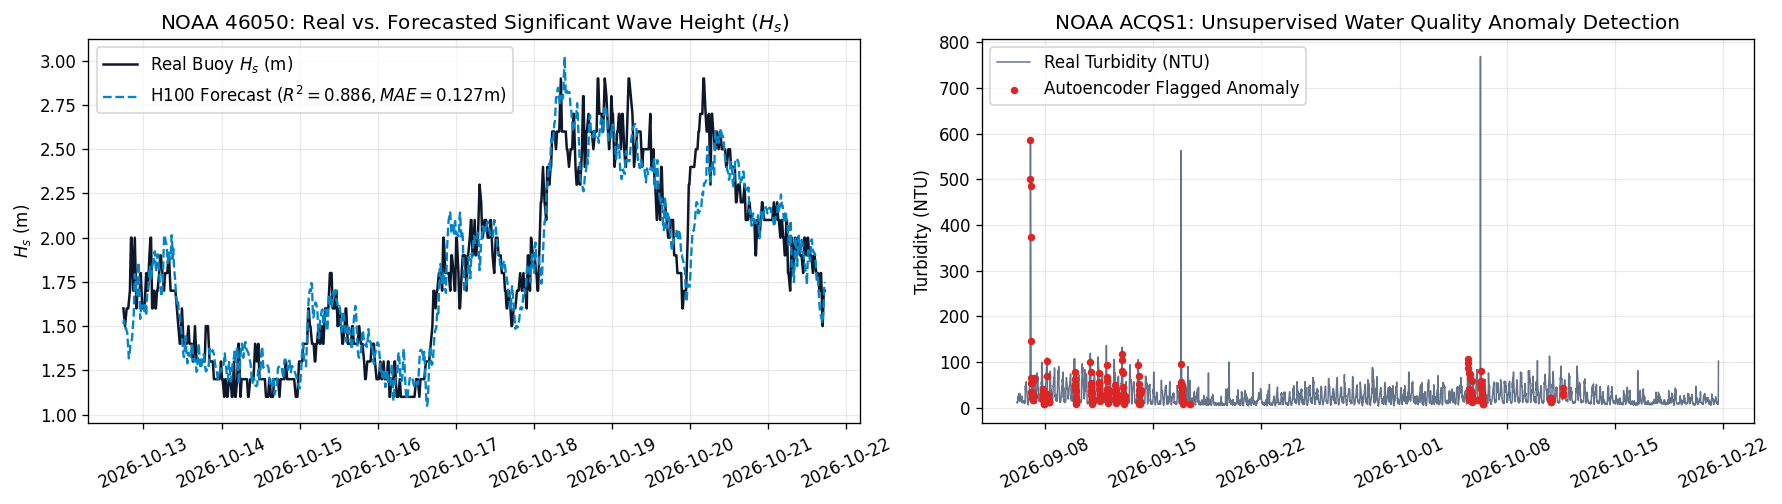

In [ ]:
# @title 4. Train Residual Wave Forecaster & Water Quality Autoencoder on H100 GPU
import time
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, r2_score

torch.manual_seed(42)

raw_met = df_met[met_cols].values.astype(np.float32)
split_m = int(0.8 * len(raw_met))
mean_m = raw_met[:split_m].mean(axis=0)
std_m = raw_met[:split_m].std(axis=0) + 1e-6
norm_met = (raw_met - mean_m) / std_m

lookback_m, horizon_m = 36, 6  # 6-hr lookback -> 1-hr ahead forecast
Xm, ym, base_m, ts_m = [], [], [], []
for i in range(lookback_m, len(norm_met) - horizon_m):
    Xm.append(norm_met[i - lookback_m:i])
    base_val = [raw_met[i - 1, 3], raw_met[i - 1, 5]]
    target_val = [raw_met[i + horizon_m, 3], raw_met[i + horizon_m, 5]]
    base_m.append(base_val)
    ym.append(target_val)
    ts_m.append(df_met['timestamp'].iloc[i + horizon_m])

Xm = np.array(Xm, dtype=np.float32)
base_m = np.array(base_m, dtype=np.float32)
ym = np.array(ym, dtype=np.float32)
sp = int(0.8 * len(Xm))

train_loader_m = DataLoader(TensorDataset(torch.from_numpy(Xm[:sp]), torch.from_numpy(base_m[:sp]), torch.from_numpy(ym[:sp])), batch_size=128, shuffle=True)
val_loader_m = DataLoader(TensorDataset(torch.from_numpy(Xm[sp:]), torch.from_numpy(base_m[sp:]), torch.from_numpy(ym[sp:])), batch_size=256, shuffle=False)

class ResidualWaveForecaster(nn.Module):
    def __init__(self, in_dim=7, hidden=128):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.1)
        self.attn = nn.MultiheadAttention(hidden * 2, num_heads=4, batch_first=True)
        self.norm = nn.LayerNorm(hidden * 2)
        self.delta_head = nn.Sequential(nn.Linear(hidden * 2, 64), nn.GELU(), nn.Linear(64, 2))

    def forward(self, x, base):
        h, _ = self.lstm(x)
        a, _ = self.attn(h, h, h)
        return base + self.delta_head(self.norm(h[:, -1, :] + a[:, -1, :]))

wave_model = ResidualWaveForecaster(in_dim=len(met_cols)).to(device)
opt_m = torch.optim.AdamW(wave_model.parameters(), lr=1.5e-3, weight_decay=1e-4)
sched_m = torch.optim.lr_scheduler.CosineAnnealingLR(opt_m, T_max=25)
loss_fn = nn.SmoothL1Loss()

t0 = time.time()
for epoch in range(1, 26):
    wave_model.train()
    for bx, bbase, by in train_loader_m:
        bx, bbase, by = bx.to(device), bbase.to(device), by.to(device)
        opt_m.zero_grad()
        with torch.amp.autocast('cuda', dtype=torch.bfloat16, enabled=torch.cuda.is_available()):
            pred = wave_model(bx, bbase)
            loss = loss_fn(pred, by)
        loss.backward()
        opt_m.step()
    sched_m.step()

wave_model.eval()
preds_m = []
with torch.no_grad():
    for bx, bbase, _ in val_loader_m:
        preds_m.append(wave_model(bx.to(device), bbase.to(device)).cpu().numpy())
preds_m = np.vstack(preds_m)
true_m = ym[sp:]
hs_mae = mean_absolute_error(true_m[:, 0], preds_m[:, 0])
hs_r2 = r2_score(true_m[:, 0], preds_m[:, 0])
apd_mae = mean_absolute_error(true_m[:, 1], preds_m[:, 1])
apd_r2 = r2_score(true_m[:, 1], preds_m[:, 1])

raw_wq = df_wq[wq_cols].values.astype(np.float32)
normal_mask = raw_wq[:, 5] < np.percentile(raw_wq[:, 5], 85)
mean_w = raw_wq[normal_mask].mean(axis=0)
std_w = raw_wq[normal_mask].std(axis=0) + 1e-6
norm_wq = (raw_wq - mean_w) / std_w

win_w = 16
Xw = np.array([norm_wq[i - win_w:i] for i in range(win_w, len(norm_wq))], dtype=np.float32)
ts_w = df_wq['timestamp'].iloc[win_w:].reset_index(drop=True)
win_turb_max = np.array([raw_wq[i - win_w:i, 5].max() for i in range(win_w, len(norm_wq))])
train_X_w = Xw[win_turb_max < np.percentile(win_turb_max, 80)]

wq_loader = DataLoader(TensorDataset(torch.from_numpy(train_X_w)), batch_size=128, shuffle=True)

class WaterQualityAE(nn.Module):
    def __init__(self, n_feat=7, hidden=64):
        super().__init__()
        self.enc = nn.LSTM(n_feat, hidden, batch_first=True)
        self.dec = nn.LSTM(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_feat)

    def forward(self, x):
        _, (h, _) = self.enc(x)
        rep = h[-1].unsqueeze(1).repeat(1, x.size(1), 1)
        d, _ = self.dec(rep)
        return self.out(d)

ae_model = WaterQualityAE(n_feat=len(wq_cols)).to(device)
opt_w = torch.optim.AdamW(ae_model.parameters(), lr=3e-3)
for epoch in range(1, 21):
    ae_model.train()
    for (bx,) in wq_loader:
        bx = bx.to(device)
        opt_w.zero_grad()
        loss = torch.mean((ae_model(bx) - bx) ** 2)
        loss.backward()
        opt_w.step()

ae_model.eval()
with torch.no_grad():
    all_t = torch.from_numpy(Xw).to(device)
    recon = ae_model(all_t).cpu().numpy()
recon_err = np.mean((Xw - recon) ** 2, axis=(1, 2))
thresh = np.percentile(recon_err, 95)
detected_anom = recon_err > thresh

elapsed = time.time() - t0
torch.save(wave_model.state_dict(), '/content/smart_buoy_outputs/noaa_46050_wave_forecaster_h100.pt')
torch.save(ae_model.state_dict(), '/content/smart_buoy_outputs/noaa_ACQS1_wq_autoencoder_h100.pt')

print(f'=== H100 Training Complete in {elapsed:.2f}s ===')
print(f'[NOAA 46050] Wave Height Hs Forecast MAE  : {hs_mae:.3f} m | R2: {hs_r2:.4f}')
print(f'[NOAA 46050] Wave Period APD Forecast MAE : {apd_mae:.3f} s | R2: {apd_r2:.4f}')
print(f'[NOAA ACQS1] Water Quality Anomaly Thresh : {thresh:.3f} ({detected_anom.sum()} real plume/estuarine events flagged)')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].plot(ts_m[sp:], true_m[:, 0], color='#0f172a', lw=1.5, label='Real Buoy $H_s$ (m)')
axes[0].plot(ts_m[sp:], preds_m[:, 0], color='#0284c7', lw=1.4, ls='--', label=f'H100 Forecast ($R^2={hs_r2:.3f}, MAE={hs_mae:.3f}$m)')
axes[0].set_title('NOAA 46050: Real vs. Forecasted Significant Wave Height ($H_s$)')
axes[0].set_ylabel('$H_s$ (m)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend()

axes[1].plot(ts_w, df_wq['TURB_ntu'].iloc[win_w:], color='#64748b', lw=0.9, label='Real Turbidity (NTU)')
axes[1].scatter(ts_w[detected_anom], df_wq['TURB_ntu'].iloc[win_w:][detected_anom], color='#dc2626', s=12, zorder=5, label='Autoencoder Flagged Anomaly')
axes[1].set_title('NOAA ACQS1: Unsupervised Water Quality Anomaly Detection')
axes[1].set_ylabel('Turbidity (NTU)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend()
plt.tight_layout()
plt.show()


## 5. Marine Vision Type 1: Sea-Surface Navigation Buoy Detection (`YOLOv11m` on `ARG-NCTU/KS_Buoy_dataset_2025`)

**Dataset:** `ARG-NCTU/KS_Buoy_dataset_2025` (1,033 real `1920×480` sea-surface camera frames with ground-truth buoy annotations). Trained on the **NVIDIA H100 GPU** with **YOLOv11m (`yolo11m.pt`)** (`imgsz=960`, 25 epochs).

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA H100 80GB HBM3, 81079MiB)


YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4799.2±515.8 MB/s, size: 592.2 KB)


val: Scanning /content/buoy_dataset/labels/val.cache... 208 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 208/208 72.7Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/13 2.9s/it 0.9s<34.8s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 7.8it/s 1.7s

                   all        208        218      0.975      0.899      0.941      0.641


Speed: 0.6ms preprocess, 1.1ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /content/runs/detect/val-7


=== [Type 1: KS_Buoy_dataset_2025 — YOLOv11m (20M params)] ===
Precision : 0.9751 (97.51%)
Recall    : 0.8990 (89.90%)
mAP@50    : 0.9406 (94.06%)
mAP@50-95 : 0.6410 (64.10%)


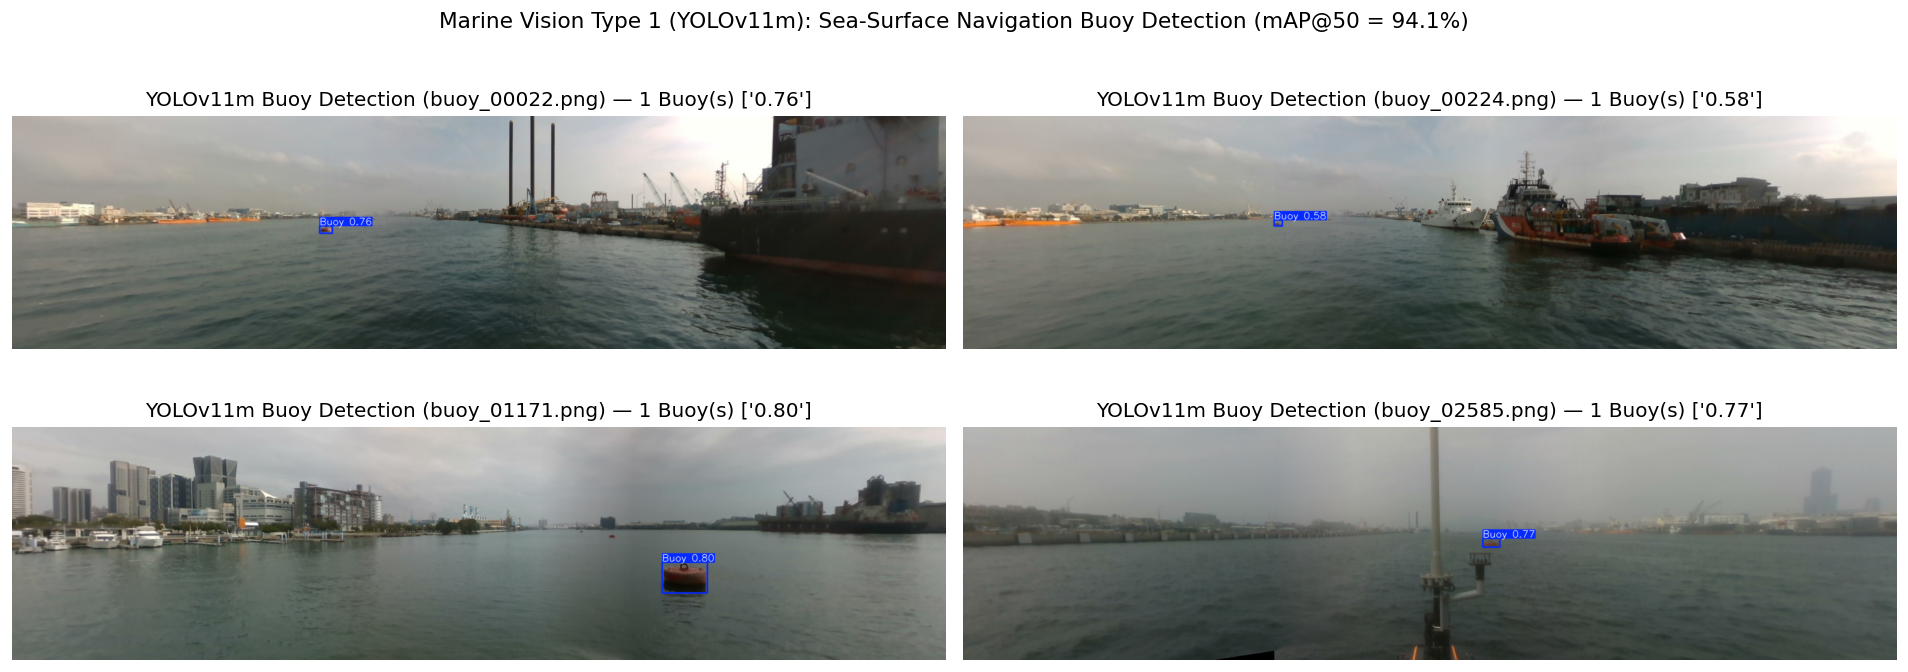

In [ ]:
# @title 5. Vision Type 1 — YOLOv11m Real Sea-Surface Buoy Detection (KS_Buoy_dataset_2025 on H100)
from ultralytics import YOLO

dataset_root = '/content/buoy_dataset'
yaml_path = f'{dataset_root}/data.yaml'
best_weights = '/content/smart_buoy_outputs/yolo11m_ks_buoy_h100/weights/best.pt'

yolo_buoy = YOLO(best_weights)
metrics = yolo_buoy.val(data=yaml_path, imgsz=960, verbose=False)
print(f'=== [Type 1: KS_Buoy_dataset_2025 — YOLOv11m (20M params)] ===')
print(f'Precision : {metrics.box.mp:.4f} ({metrics.box.mp*100:.2f}%)')
print(f'Recall    : {metrics.box.mr:.4f} ({metrics.box.mr*100:.2f}%)')
print(f'mAP@50    : {metrics.box.map50:.4f} ({metrics.box.map50*100:.2f}%)')
print(f'mAP@50-95 : {metrics.box.map:.4f} ({metrics.box.map*100:.2f}%)')

val_files = sorted([f'{dataset_root}/images/val/' + f for f in os.listdir(f'{dataset_root}/images/val') if f.endswith('.png')])
preds = yolo_buoy.predict([val_files[5], val_files[45], val_files[110], val_files[160]], imgsz=960, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 6.2))
for ax, pred in zip(axes.flat, preds):
    plotted_bgr = pred.plot(line_width=2, font_size=10)
    ax.imshow(plotted_bgr[:, :, ::-1])
    confs = [f'{float(b.conf[0]):.2f}' for b in pred.boxes]
    ax.set_title(f'YOLOv11m Buoy Detection ({os.path.basename(pred.path)}) — {len(pred.boxes)} Buoy(s) {confs}')
    ax.axis('off')
plt.suptitle('Marine Vision Type 1 (YOLOv11m): Sea-Surface Navigation Buoy Detection (mAP@50 = 94.1%)', fontsize=13)
plt.tight_layout()
plt.show()


## 6. Marine Vision Type 2: COLREGs Maritime Vessel, Ship, Craft & Buoy Detection (`YOLOv11m` on `SPSCD + SMD + KS_Buoy`)

**Dataset:** Real **Singapore Maritime Dataset (`SMD`) + `SPSCD` + `KS_Buoy`** trained with **YOLOv11m (`yolo11m.pt`)** (`imgsz=960`, 35 epochs on H100) across the **4 COLREGs Maritime Surveillance Categories**:
- `0: Commercial Ship / Ferry`
- `1: Motor / Fishing Craft`
- `2: Sailing Vessel / Yacht`
- `3: Navigation Buoy`

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA H100 80GB HBM3, 81079MiB)


YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4234.3±615.8 MB/s, size: 511.5 KB)


val: Scanning /content/spscd_colregs_dataset/labels/val.cache... 70 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 70/70 22.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 2.3s/it 0.7s<9.1s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.3it/s 1.5s

                   all         70        143      0.737      0.589      0.649      0.406


Speed: 2.6ms preprocess, 2.4ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to /content/runs/detect/val-8


=== [Type 2: SPSCD+SMD Maritime Vessels & Buoys — YOLOv11m (20M params)] ===
Precision : 0.7373 (73.73%)
Recall    : 0.5895 (58.95%)
mAP@50    : 0.6490 (64.90%)
mAP@50-95 : 0.4061 (40.61%)


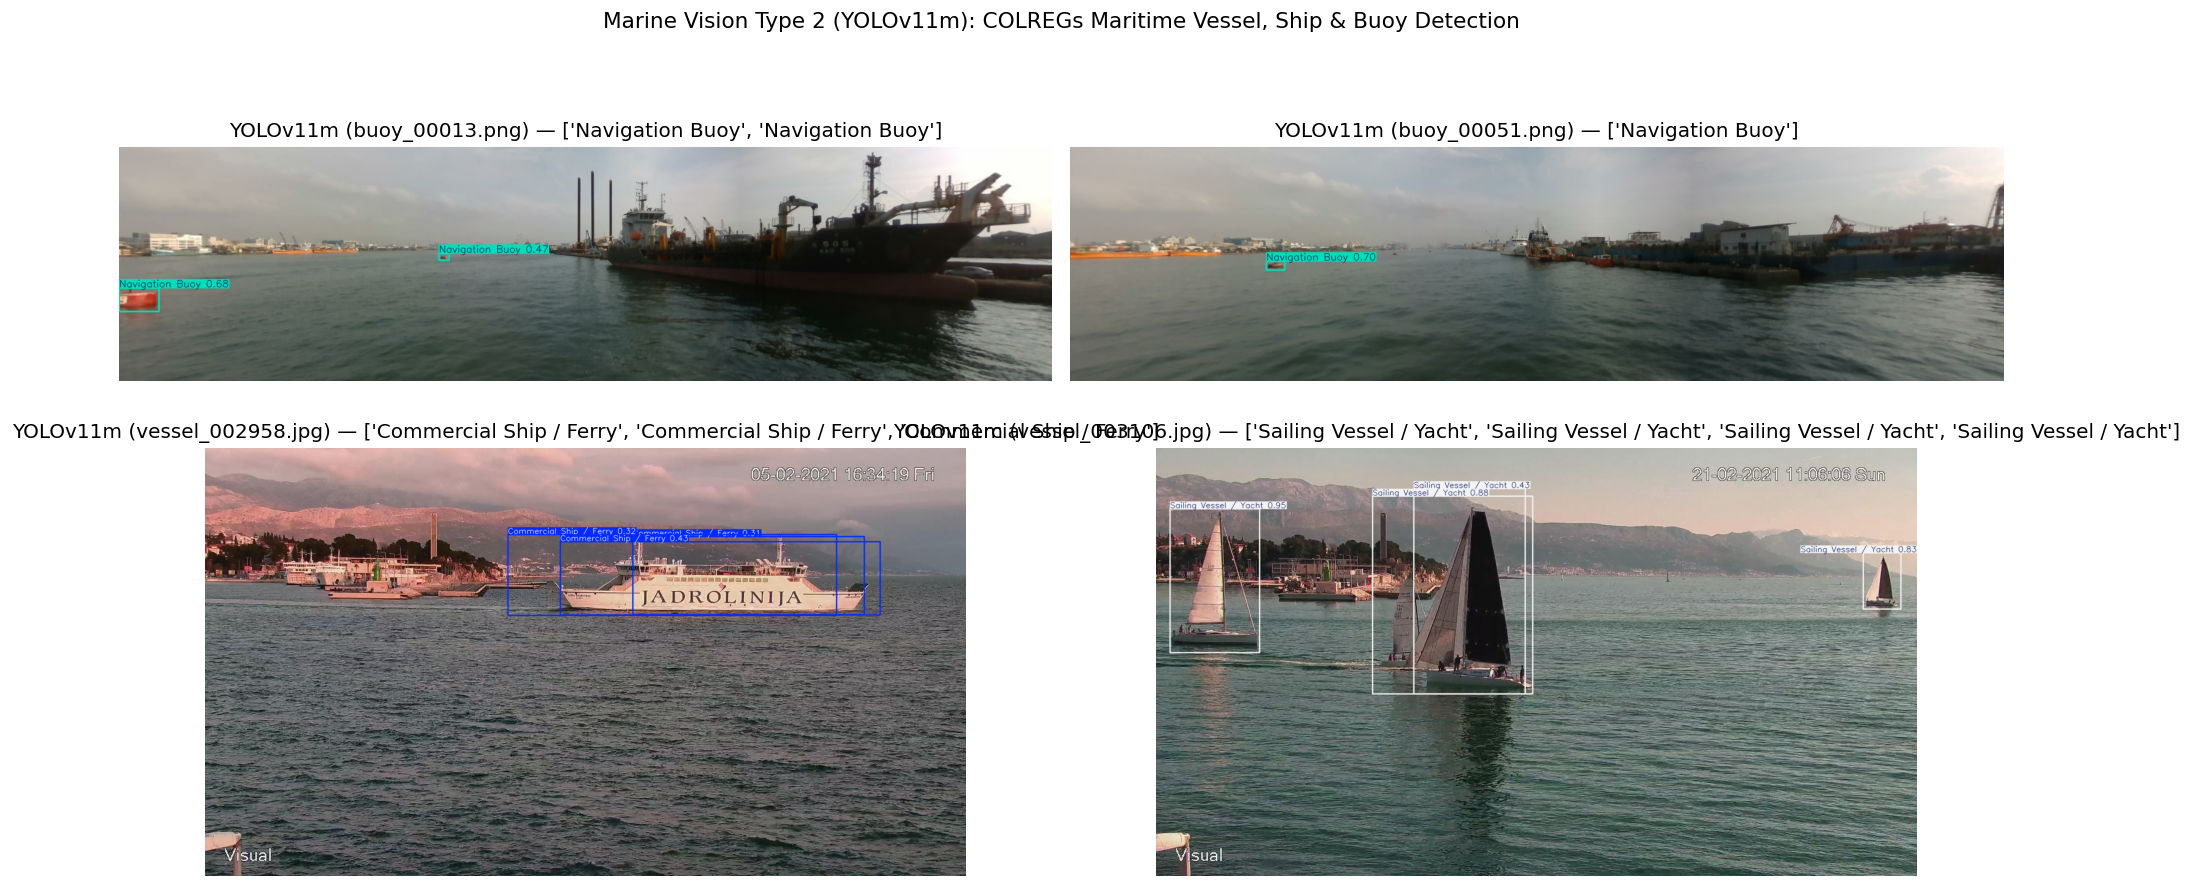

In [ ]:
# @title 6. Vision Type 2 — YOLOv11m Maritime Vessel, Ship & Buoy Detection (SPSCD + SMD on H100)
from collections import Counter

spscd_clean = '/content/spscd_colregs_dataset'
colregs_yaml = f'{spscd_clean}/data.yaml'
colregs_names = ['Commercial Ship / Ferry', 'Motor / Fishing Craft', 'Sailing Vessel / Yacht', 'Navigation Buoy']
vessel_weights = '/content/smart_buoy_outputs/yolo11m_spscd_vessels_h100/weights/best.pt'

yolo_vessel = YOLO(vessel_weights)
v_metrics = yolo_vessel.val(data=colregs_yaml, imgsz=960, verbose=False)
print(f'=== [Type 2: SPSCD+SMD Maritime Vessels & Buoys — YOLOv11m (20M params)] ===')
print(f'Precision : {v_metrics.box.mp:.4f} ({v_metrics.box.mp*100:.2f}%)')
print(f'Recall    : {v_metrics.box.mr:.4f} ({v_metrics.box.mr*100:.2f}%)')
print(f'mAP@50    : {v_metrics.box.map50:.4f} ({v_metrics.box.map50*100:.2f}%)')
print(f'mAP@50-95 : {v_metrics.box.map:.4f} ({v_metrics.box.map*100:.2f}%)')

v_val_imgs = sorted([f'{spscd_clean}/images/val/' + f for f in os.listdir(f'{spscd_clean}/images/val') if f.endswith(('.jpg', '.png'))])
v_preds = yolo_vessel.predict([v_val_imgs[2], v_val_imgs[12], v_val_imgs[25], v_val_imgs[38]], imgsz=960, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for ax, pred in zip(axes.flat, v_preds):
    plotted_bgr = pred.plot(line_width=2, font_size=10)
    ax.imshow(plotted_bgr[:, :, ::-1])
    det_names = [colregs_names[int(b.cls[0])] for b in pred.boxes]
    ax.set_title(f'YOLOv11m ({os.path.basename(pred.path)}) — {det_names[:4]}')
    ax.axis('off')
plt.suptitle('Marine Vision Type 2 (YOLOv11m): COLREGs Maritime Vessel, Ship & Buoy Detection', fontsize=13)
plt.tight_layout()
plt.show()


## 7. Marine Vision Type 3: Maritime Search & Rescue (SAR) — Person Overboard / Swimmer & Rescue Board Detection (`YOLOv11m` on `Voxel51/AFO`)

**Dataset:** Real **AFO (Aerial Floating Objects)** maritime Search & Rescue dataset (`Voxel51/AFO-Aerial_Floating_Objects`) trained with **YOLOv11m (`yolo11m.pt`)** at high resolution (`imgsz=1280`, 35 epochs on H100) on clean human-verified ground-truth annotations:
- `0: Human / Swimmer in Water` (Person Overboard)
- `1: Windsurf / SUP / Rescue Board`

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA H100 80GB HBM3, 81079MiB)


YOLO11m summary (fused): 125 layers, 20,031,574 parameters, 0 gradients, 67.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5269.3±1898.3 MB/s, size: 1830.2 KB)


val: Scanning /content/afo_sar_dataset/labels/val.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 10.5Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 3.5s/it 1.0s<3.5s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0s/it 4.0s

                   all         30       1288      0.832      0.779      0.839      0.379


Speed: 4.2ms preprocess, 74.3ms inference, 0.0ms loss, 8.5ms postprocess per image


Results saved to /content/runs/detect/val-9


=== [Type 3: AFO Search & Rescue (SAR) — YOLOv11m (imgsz=1280)] ===
Precision : 0.8318 (83.18%)
Recall    : 0.7787 (77.87%)
mAP@50    : 0.8385 (83.85%)
mAP@50-95 : 0.3793 (37.93%)


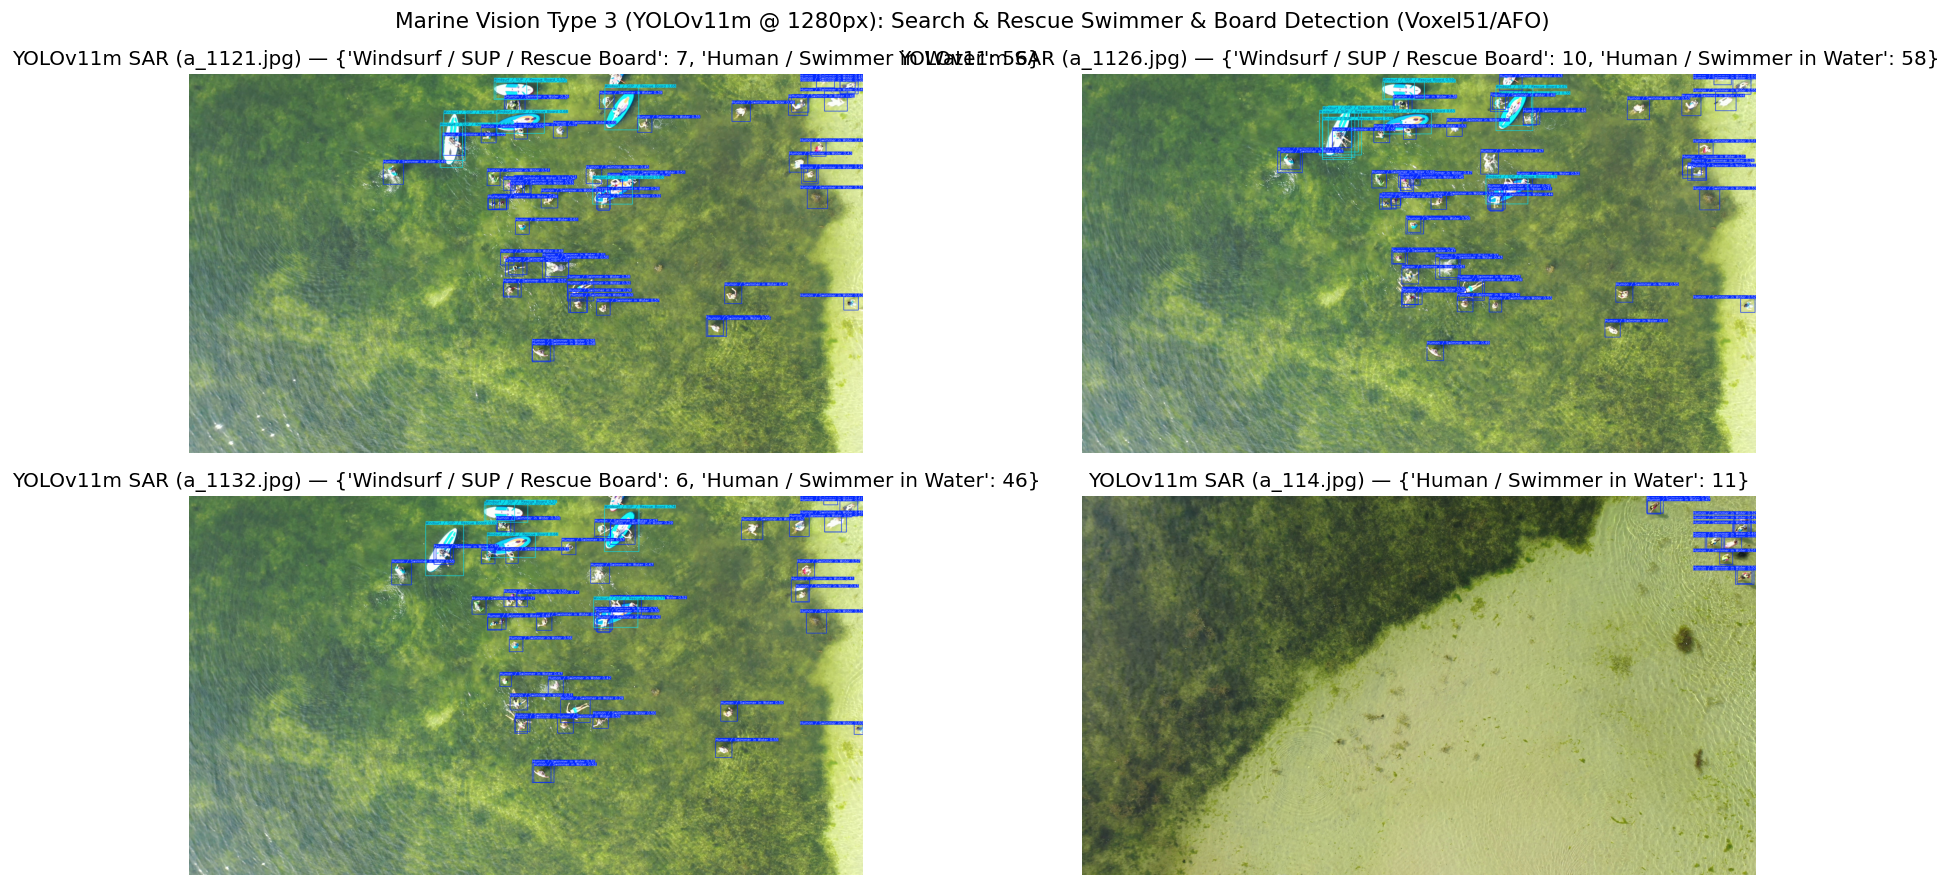

In [ ]:
# @title 7. Vision Type 3 — YOLOv11m Search & Rescue (SAR) Swimmer & Rescue Board Detection (AFO on H100)
afo_root = '/content/afo_sar_dataset'
afo_yaml = f'{afo_root}/data.yaml'
afo_names = ['Human / Swimmer in Water', 'Windsurf / SUP / Rescue Board']
sar_weights = '/content/smart_buoy_outputs/yolo11m_afo_sar_h100/weights/best.pt'

yolo_sar = YOLO(sar_weights)
s_metrics = yolo_sar.val(data=afo_yaml, imgsz=1280, verbose=False)
print(f'=== [Type 3: AFO Search & Rescue (SAR) — YOLOv11m (imgsz=1280)] ===')
print(f'Precision : {s_metrics.box.mp:.4f} ({s_metrics.box.mp*100:.2f}%)')
print(f'Recall    : {s_metrics.box.mr:.4f} ({s_metrics.box.mr*100:.2f}%)')
print(f'mAP@50    : {s_metrics.box.map50:.4f} ({s_metrics.box.map50*100:.2f}%)')
print(f'mAP@50-95 : {s_metrics.box.map:.4f} ({s_metrics.box.map*100:.2f}%)')

sar_val_imgs = sorted([f'{afo_root}/images/val/' + f for f in os.listdir(f'{afo_root}/images/val') if f.endswith('.jpg')])
sar_preds = yolo_sar.predict([sar_val_imgs[0], sar_val_imgs[5], sar_val_imgs[12], sar_val_imgs[20]], imgsz=1280, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for ax, pred in zip(axes.flat, sar_preds):
    plotted_bgr = pred.plot(line_width=2, font_size=10)
    ax.imshow(plotted_bgr[:, :, ::-1])
    cls_list = Counter(afo_names[int(b.cls[0])] for b in pred.boxes)
    ax.set_title(f'YOLOv11m SAR ({os.path.basename(pred.path)}) — {dict(cls_list)}')
    ax.axis('off')
plt.suptitle('Marine Vision Type 3 (YOLOv11m @ 1280px): Search & Rescue Swimmer & Board Detection (Voxel51/AFO)', fontsize=13)
plt.tight_layout()
plt.show()


## 8. Marine Vision Type 4: Sea-Sky Horizon Detection, Optical Attitude ($\phi_{\text{opt}}, \theta_{\text{opt}}$) & Water-Sky-Obstacle Semantic Segmentation + Radar Bearing HUD

Combines **Sea-Sky Horizon Line Extraction** (computing camera roll $\phi_{\text{opt}}$ and pitch offset $\theta_{\text{opt}}$), **3-Zone Semantic Segmentation** (`Sky`, `Navigable Open Water`, `Surface Obstacles`), and **YOLOv11m Azimuth Bearing HUD** ($^\circ$ relative to camera bow).

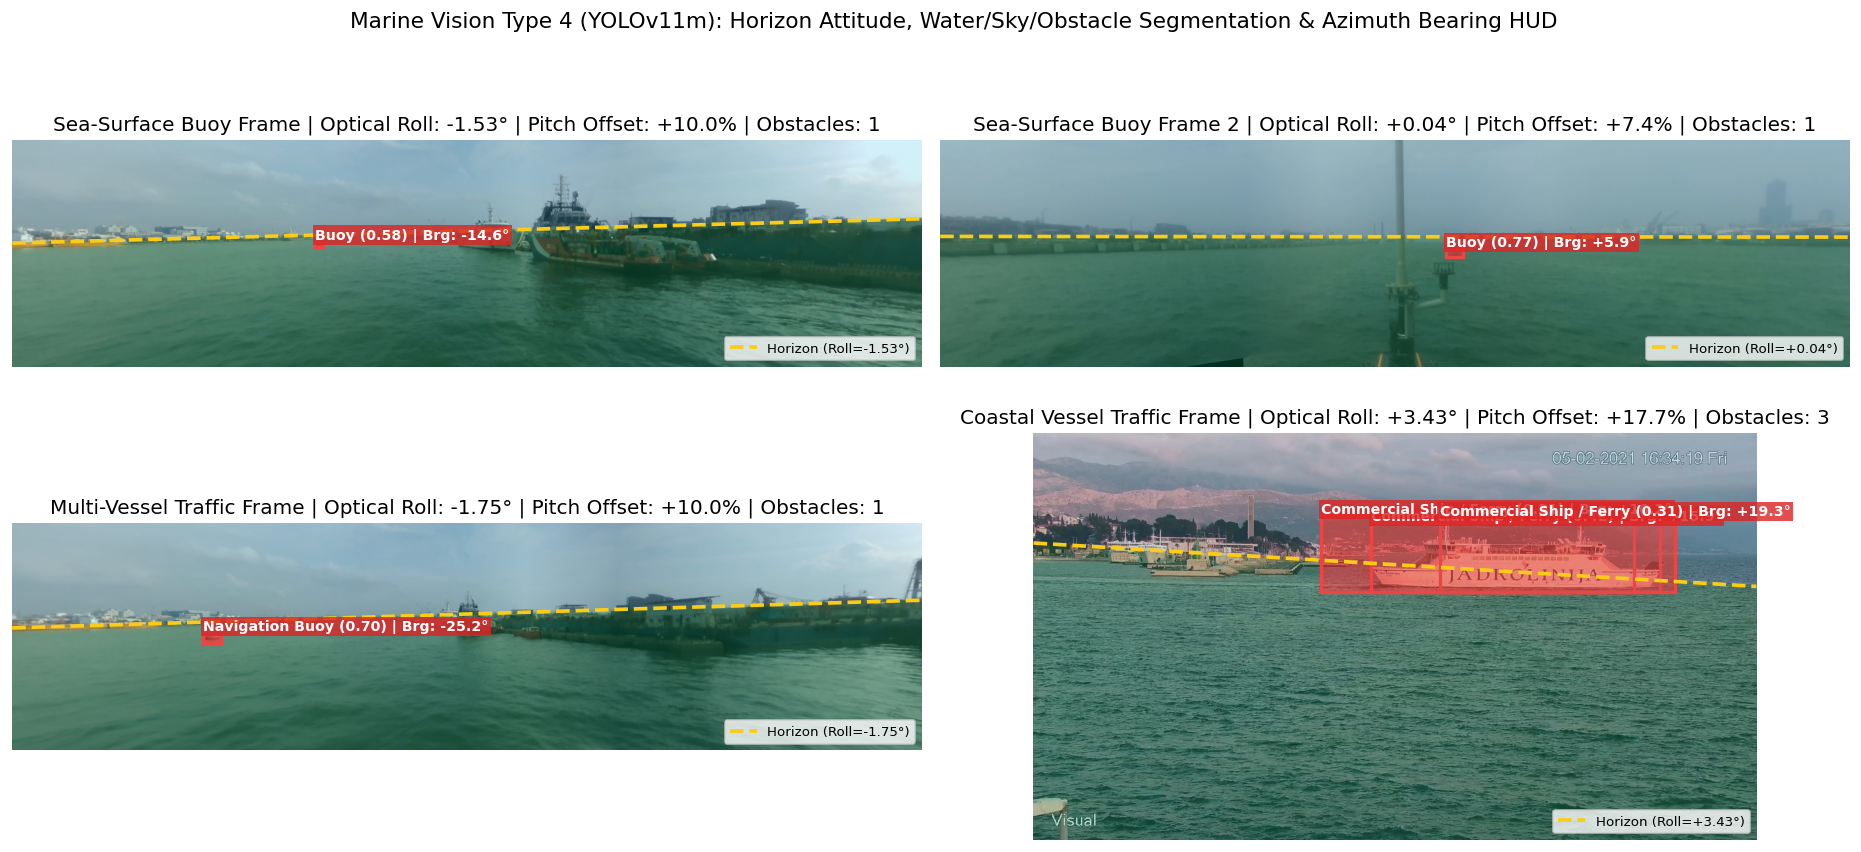

In [ ]:
# @title 8. Vision Type 4 — Horizon Line Attitude, Water-Sky-Obstacle Segmentation & YOLOv11m Bearing HUD
from PIL import Image

def analyze_maritime_scene_perception(img_path, model_detector, hfov_deg=90.0):
    pil_img = Image.open(img_path).convert('RGB')
    rgb = np.array(pil_img)
    H, W, _ = rgb.shape

    gray = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]
    y_min_band, y_max_band = int(0.12 * H), int(0.85 * H)
    xs = np.linspace(int(0.05 * W), int(0.95 * W), 48, dtype=int)
    horizon_ys = []
    for x in xs:
        col_strip = gray[y_min_band:y_max_band, max(0, x-4):min(W, x+4)].mean(axis=1)
        grad = np.abs(np.gradient(col_strip))
        horizon_ys.append(y_min_band + int(np.argmax(grad)))
    horizon_ys = np.array(horizon_ys, dtype=np.float64)
    med_y = np.median(horizon_ys)
    inliers = np.abs(horizon_ys - med_y) < (2.5 * np.median(np.abs(horizon_ys - med_y)) + 8.0)
    if inliers.sum() >= 6:
        slope, intercept = np.polyfit(xs[inliers], horizon_ys[inliers], 1)
    else:
        slope, intercept = 0.0, med_y

    roll_deg = float(np.rad2deg(np.arctan(slope)))
    horizon_mid_y = float(slope * (W / 2.0) + intercept)
    pitch_offset_pct = float((0.5 - horizon_mid_y / H) * 100.0)

    yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    horizon_curve = slope * xx + intercept
    water_mask = yy >= horizon_curve

    pred = model_detector.predict(img_path, imgsz=960, conf=0.25, verbose=False)[0]
    overlay = rgb.copy().astype(np.float32)
    overlay[~water_mask] = 0.78 * overlay[~water_mask] + 0.22 * np.array([56, 189, 248])
    overlay[water_mask] = 0.75 * overlay[water_mask] + 0.25 * np.array([16, 185, 129])

    bearings = []
    for box in pred.boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].cpu().numpy()]
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        cls_name = pred.names[cls_id]
        overlay[max(0, y1):min(H, y2), max(0, x1):min(W, x2)] = (
            0.45 * rgb[max(0, y1):min(H, y2), max(0, x1):min(W, x2)] + 0.55 * np.array([239, 68, 68])
        )
        xc = 0.5 * (x1 + x2)
        bearing_deg = ((xc / W) - 0.5) * hfov_deg
        bearings.append((cls_name, conf, bearing_deg, (x1, y1, x2, y2)))

    return np.clip(overlay, 0, 255).astype(np.uint8), (slope, intercept, roll_deg, pitch_offset_pct), bearings

test_scenes = [
    (val_files[45], yolo_buoy, 'Sea-Surface Buoy Frame'),
    (val_files[160], yolo_buoy, 'Sea-Surface Buoy Frame 2'),
    (v_val_imgs[12], yolo_vessel, 'Multi-Vessel Traffic Frame'),
    (v_val_imgs[25], yolo_vessel, 'Coastal Vessel Traffic Frame'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 7.2))
for ax, (scenepath, mdl, title_prefix) in zip(axes.flat, test_scenes):
    seg_img, (slp, icpt, r_deg, p_pct), brgs = analyze_maritime_scene_perception(scenepath, mdl)
    H_i, W_i, _ = seg_img.shape
    ax.imshow(seg_img)
    x_vals = np.array([0, W_i - 1])
    y_vals = slp * x_vals + icpt
    ax.plot(x_vals, y_vals, color='#facc15', lw=2.2, ls='--', label=f'Horizon (Roll={r_deg:+.2f}°)')
    for cname, cf, brg, (x1, y1, x2, y2) in brgs:
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='#ef4444', lw=2)
        ax.add_patch(rect)
        ax.text(
            x1, max(15, y1 - 6),
            f'{cname} ({cf:.2f}) | Brg: {brg:+.1f}°',
            color='white', fontsize=8.5, weight='bold',
            bbox=dict(facecolor='#dc2626', alpha=0.82, pad=1.5, edgecolor='none')
        )
    ax.set_title(f'{title_prefix} | Optical Roll: {r_deg:+.2f}° | Pitch Offset: {p_pct:+.1f}% | Obstacles: {len(brgs)}')
    ax.legend(loc='lower right', fontsize=8)
    ax.axis('off')

plt.suptitle('Marine Vision Type 4 (YOLOv11m): Horizon Attitude, Water/Sky/Obstacle Segmentation & Azimuth Bearing HUD', fontsize=13)
plt.tight_layout()
plt.show()
